# 07 · Escenarios hipotéticos (Fase 10)
Se cambia **una** circunstancia en las personas que nacieron en Q1 y se observa cómo cambia la probabilidad media que predice el modelo.

> ⚠️ Son simulaciones del modelo: describen **asociaciones**, no lo que pasaría si una política cambiara esa circunstancia.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import display, Markdown
pd.set_option("display.max_columns", 30)
from src.config import *
df = pd.read_parquet(PROCESSED / "emovi_movilidad.parquet")
q1 = df[df.sigue_q1.notna()]
from src.models import train as T
tr, te = T.split(df)
tabla, modelos = T.compare(tr, te, T.NUM, T.CAT)
elegido, mejor_auc = T.choose(tabla)
modelo = modelos[elegido]
from src.evaluation import interpret as I
from src.visualization import plots as V
import matplotlib.pyplot as plt

,Escenario,Personas afectadas,Prob. media de seguir en Q1,Cambio (puntos %)
0,Situación observada,2674,0.517,0.000
1,Madre con secundaria (en vez de primaria o menos),2139,0.496,-1.953
2,Crecer en ciudad mediana (en vez de pueblo),1802,0.479,-7.390
3,Crecer en el Norte (en vez del Sur),1355,0.424,-20.943
4,Tono de piel claro (en vez de oscuro),578,0.538,1.500


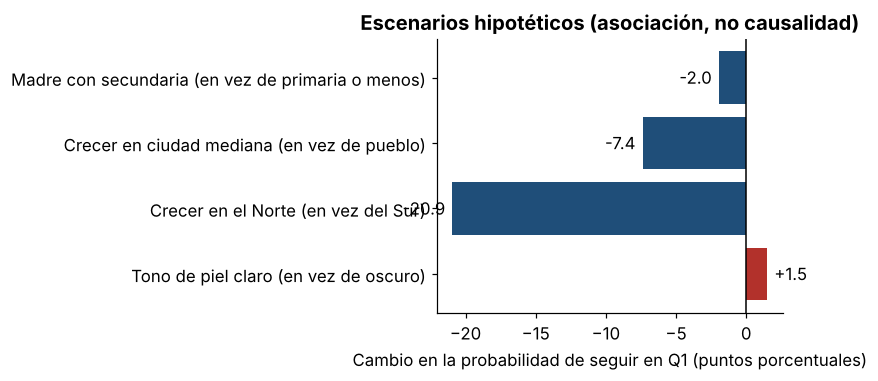

In [2]:
esc = I.scenarios(modelo, q1, T.NUM, T.CAT)
esc.to_csv(TABLES / "escenarios.csv", index=False); display(esc); V.escenarios(esc); plt.show()

**Lectura:** el escenario con mayor asociación es haber crecido en el Norte en vez del Sur (≈ −21 puntos). Esto sugiere que la geografía de oportunidades (mercados laborales y servicios) pesa tanto como las características del hogar.

## Escenarios del roadmap (Fase 10), con incertidumbre
Se usa el **modelo de mediación** (circunstancias de origen + escolaridad propia + empleo), porque los escenarios educativos y laborales lo requieren. La incertidumbre (IC 95%) sale de reestimar el modelo en 100 remuestreos bootstrap.

| Escenario | Variables que cambian | Variables constantes |
|---|---|---|
| Continuidad | Ninguna | Todas |
| Mejora educativa | Escolaridad +1 nivel | Origen, empleo |
| Educación sin mejora laboral | Escolaridad +1 y todos informales | Origen |
| Educación con empleo formal | Escolaridad +1 y los informales pasan a formales | Origen; los "no ocupados" no cambian |
| Reducción de brecha territorial | El Sur toma la región Centro | Todo lo demás |
| Choque adverso | **RECHAZADO**: no hay variables de choque en la EMOVI y sería extrapolar | — |

,Escenario,% predicho que sigue en Q1,Cambio vs continuidad (pts),IC 95% inf,IC 95% sup
0,Continuidad (situación observada),51.8,0.0,0.0,0.0
1,Mejora educativa (+1 nivel),41.8,-10.1,-11.9,-8.2
2,Mejora educativa sin mejora laboral (todos inf...,42.9,-8.9,-11.0,-6.8
3,Mejora educativa con empleo formal,35.3,-16.6,-20.3,-13.1
4,Reducción de brecha territorial (Sur con perfi...,46.7,-5.2,-7.0,-2.8
5,Choque adverso de empleo o ingreso,NaN,NaN,NaN,NaN


Personas: 2633


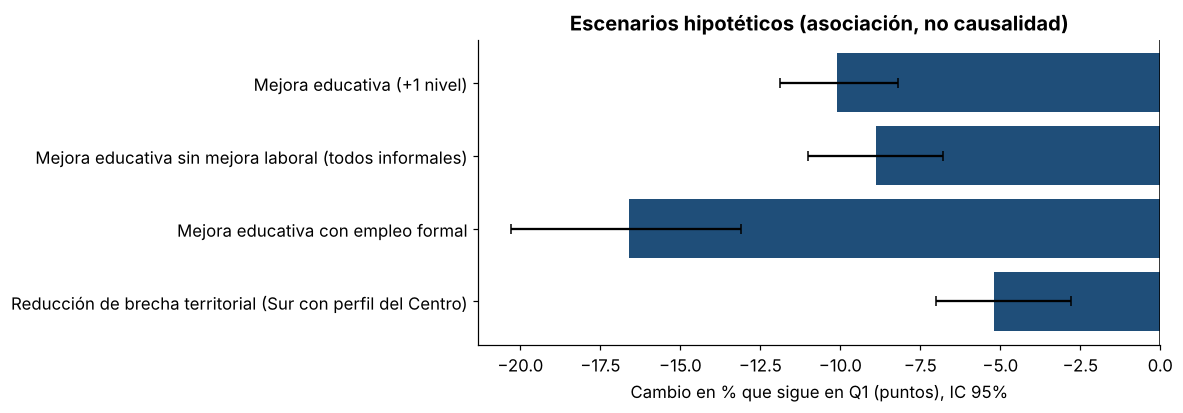

In [3]:
from src.evaluation import extra as X
er, n = X.escenarios_roadmap(df, n_boot=100); er.to_csv(TABLES / "escenarios_roadmap.csv", index=False); display(er); print("Personas:", n)
e2 = er.dropna().iloc[1:]
fig, ax = plt.subplots(figsize=(8, 3.6)); y = range(len(e2))
ax.barh(list(y), e2["Cambio vs continuidad (pts)"], xerr=[e2["Cambio vs continuidad (pts)"] - e2["IC 95% inf"], e2["IC 95% sup"] - e2["Cambio vs continuidad (pts)"]], color="#1f4e79", capsize=3)
ax.set_yticks(list(y), e2.Escenario); ax.invert_yaxis(); ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Cambio en % que sigue en Q1 (puntos), IC 95%"); ax.set_title("Escenarios hipotéticos (asociación, no causalidad)")
fig.savefig(FIGURES / "14_escenarios_roadmap.png", bbox_inches="tight", dpi=200); plt.show()

**Lectura (regla de lenguaje del roadmap):** *bajo el escenario hipotético de que cada persona hubiera alcanzado un nivel educativo más, y manteniendo las relaciones estimadas,* la proporción que sigue en Q1 bajaría de ≈52% a ≈42% (−10 puntos). *Si además los empleos informales fueran formales,* bajaría a ≈35% (−17 puntos). En cambio, *si quienes crecieron en el Sur tuvieran el perfil regional del Centro,* bajaría ≈5 puntos.

**Por qué esto no es causal:** la escolaridad y el empleo se observan al mismo tiempo que el destino (posible causalidad inversa), hay variables omitidas (calidad escolar, redes) y un cambio masivo de escolaridad cambiaría también su valor en el mercado laboral (equilibrio general). Los escenarios muestran el **tamaño relativo** de las asociaciones, no lo que causaría una política.

**Estado de la fase:** PROPUESTA — falta la revisión humana (regla de avance del roadmap: APROBADA / APROBADA CON CAMBIOS / REABRIR / BLOQUEADA).